# Day 23 · Senses: Taste — *Eiswein watch*

**Will it freeze hard enough for ice wine?** Each grape in a bunch is one of the 51 ECMWF
ensemble forecasts. A grape turns to ice when that forecast brings at least one morning at
**−7 °C or colder** to the wine region in the next 15 days.

*Theme: Senses: Taste (23 Nov). Author: Valters Zeizis.*

## Method

Eiswein (ice wine) is pressed from grapes that froze on the vine. The water in the berry
freezes, the sugar and acid do not, so the press gives a few drops of very sweet, concentrated
juice. In Germany and Austria growers need about **−7 °C** before they pick. A warm winter can
mean no ice wine at all, and the grapes are lost to rot or birds while growers wait.

That is a probabilistic question, so it is a job for the **ensemble**:

1. Take the **night minimum** of 2 m temperature (00–06 UTC, the hours before sunrise) from
   the ECMWF ensemble (1 control + 50 perturbed members) for each of the next 15 nights.
   The open data carries it as `mn2t3` (lowest value in the past 3 h, steps ≤ 144 h) and
   `mn2t6` (past 6 h, steps 150–360 h), so: nights 1–6 = min of the 00–03 and 03–06 UTC windows,
   nights 7–15 = the 00–06 UTC window.
2. For every grid point and member, ask: *does any morning reach −7 °C?*
3. The fraction of members that say yes is the probability. That's the map shading.
4. For each wine region, draw a bunch of 51 grapes (one per member) and freeze the ones that say yes.

**Why 0.1°:** the ENS runs on a ~9 km grid, so the 0.1° open-data product keeps that detail,
while 0.25° averages it away. Wine valleys like the Ahr, Mosel and Wachau are only a few km
wide, so the finer grid matters here.

**Caveats, said plainly:** even at 0.1° (~9 km) a grid box blends valley floors,
slopes and hilltops. Vineyards on slopes are often *warmer* than the valley at dawn (cold air
drains downhill), and the minimum is taken over 00–06 UTC only (rarely, the coldest moment
falls before midnight).

**Why 2 m and not the ground?** Grape bunches hang about 0.5–1.5 m up, so 2 m air temperature is
the right height. Skin (ground) temperature can be several degrees colder on clear nights and
would exaggerate the frost. Read the map as "how likely
is a proper Eiswein frost in this area", not a vineyard-level forecast.

## Licence & attribution

**ECMWF Open Data**: Creative Commons **CC-BY-4.0**.
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`
([Terms of Use](https://apps.ecmwf.int/datasets/licences/general/)).
Borders and coastlines: **Natural Earth** (public domain).
Wine-region positions are approximate centroids, placed by hand.

## Tools

`ecmwf-opendata` ≥ 0.3.35 (retrieve; first version with the 0.1° tier) · `earthkit-data` (read) ·
`cartopy` + `matplotlib` (render)

```bash
pip install "ecmwf-opendata>=0.3.35" earthkit-data cartopy matplotlib
```

In [1]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import earthkit.data as ekd
import ecmwf.opendata
from ecmwf.opendata import Client
print("ecmwf-opendata", ecmwf.opendata.__version__)   # needs >= 0.3.35 for 0.1°

# ---- settings -------------------------------------------------------------
DATE = 0            # 0 = latest run; or e.g. "2026-11-22"
TIME = 0            # 00 UTC run
RESOL = "0p1"       # "0p1" ≈ 9 km, close to the ENS native grid; "0p25" ≈ 25 km (lighter download)
THRESH = -7.0       # °C, the Eiswein picking threshold
N_DAYS = 15         # the ENS horizon
NIGHT_MIN = True    # True: true 00–06 UTC minimum (mn2t3/mn2t6) · False: 2 m temperature at 06 UTC

# night d covers 00–06 UTC on day d of the run; mn2t3 exists to 144 h, mn2t6 beyond
STEPS = [24 * d + 6 for d in range(N_DAYS)]                     # 06 UTC each day (also used by 2t)
STEPS_MN3 = [s for d in range(N_DAYS) for s in (24 * d + 3, 24 * d + 6) if s <= 144]
STEPS_MN6 = [s for s in STEPS if s > 144]
PLAN_MIN = [("mn2t3", STEPS_MN3), ("mn2t6", STEPS_MN6)]
PLAN_2T = [("2t", STEPS)]

DATA = Path("data"); DATA.mkdir(exist_ok=True)   # repo .gitignore already skips data/*.grib2
OUT = Path("day23_taste_eiswein.png")

# ---- wine regions (approximate centroids, lat/lon) -------------------------
REGIONS = {
    # Germany: the 13 Anbaugebiete
    "Ahr":                 (50.54,  7.05),
    "Mittelrhein":         (50.15,  7.70),
    "Mosel":               (49.85,  6.95),
    "Nahe":                (49.80,  7.75),
    "Rheingau":            (50.00,  8.00),
    "Rheinhessen":         (49.85,  8.15),
    "Pfalz":               (49.30,  8.15),
    "Hess. Bergstraße":    (49.70,  8.62),
    "Franken":             (49.85, 10.10),
    "Württemberg":         (49.05,  9.25),
    "Baden":               (48.10,  7.70),
    "Saale-Unstrut":       (51.20, 11.75),
    "Sachsen":             (51.10, 13.55),
    # Austria: main areas
    "Wachau":              (48.37, 15.42),
    "Kamptal":             (48.48, 15.70),
    "Weinviertel":         (48.60, 16.30),
    "Wien":                (48.25, 16.35),
    "Thermenregion":       (47.95, 16.20),
    "Neusiedlersee":       (47.85, 16.85),
    "Südsteiermark":       (46.70, 15.50),
}
BONN = (50.72, 7.12)   # ECMWF Bonn

ecmwf-opendata 0.3.35


## Retrieve

Two things changed in the open data that this cell handles:

- **IFS Cycle 50r1 (May 2026):** the ensemble file holds the **50 perturbed members** only.
  The control is now identical to the high-resolution forecast, so it comes from
  `stream=oper, type=fc`. Together that's still 51 forecasts.
- **0.1° tier (from 20 Oct 2026):** surface and pressure-level fields come in **separate files**
  (`…-sfc` / `…-pl`), and they're published about **2 hours after** the 0.25° files.

`ecmwf-opendata` ≥ 0.3.35 handles the file split itself; we pass `levtype="sfc"` to say we only
want the surface file. The night minimum needs 21 steps × 51 forecasts ≈ 1,070 global fields:
roughly **0.7 GB at 0.25°** and **~4 GB at 0.1°** (the 06 UTC fallback is 765 fields).
Fallbacks, each announced: minimum fields missing → 2 m temperature at 06 UTC; 0.1° missing → 0.25°.

In [2]:
MEMBERS = [("oper", "fc", {}),                                   # control (= HRES since 50r1)
           ("enfo", "pf", {"number": list(range(1, 51))})]          # 50 perturbed members

def fetch(resol, plan):
    client = Client(source="ecmwf", model="ifs", resol=resol)
    if DATE == 0:
        # newest run whose LAST step is already published (0.1° lands ~2 h after 0.25°)
        last_param, last_steps = plan[-1]
        run = client.latest(stream="enfo", type="pf", time=TIME, levtype="sfc",
                            param=last_param, step=max(last_steps))
    else:
        run = DATE                                   # e.g. -1 = yesterday, or "2026-11-02"
    files = []
    for param, steps in plan:
        for stream, type_, extra in MEMBERS:
            f = DATA / f"day23_{param}_{stream}_{resol}.grib2"
            res = client.retrieve(date=run, time=TIME, stream=stream, type=type_, param=param,
                                  levtype="sfc", step=steps, target=str(f), **extra)
            files.append((param, f))
    return res.datetime, files

# try the best option first, then step down: (0.1°, minimum) -> (0.1°, 06 UTC) -> (0.25°, ...)
options = [(r, p) for r in dict.fromkeys([RESOL, "0p25"])
           for p in ([PLAN_MIN, PLAN_2T] if NIGHT_MIN else [PLAN_2T])]
for resol, plan in options:
    try:
        RUN, FILES = fetch(resol, plan)
        RESOL, PLAN = resol, plan
        break
    except Exception as err:
        print(f"{resol} / {'+'.join(p for p, _ in plan)} failed ({err}); trying next option")
else:
    raise RuntimeError("no option worked")

GRID = RESOL.replace("p", ".") + "°"
FIELD = "night minimum 2 m temperature, 00–06 UTC" if PLAN is PLAN_MIN else "2 m temperature at 06 UTC"
print("run:", RUN, "· grid:", GRID, "·", FIELD)

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


run: 2026-11-03 00:00:00 · grid: 0.1° · night minimum 2 m temperature, 00–06 UTC


## Read & process

In [7]:
def open_field(path):
    # earthkit-data reads GRIB lazily; crop to Germany/Austria BEFORE anything touches the
    # values, otherwise xarray pulls ~1,000 global 0.1° fields (tens of GB) into memory.
    da = ekd.from_source("file", str(path)).to_xarray()
    da = da[list(da.data_vars)[0]]                           # the one variable in the file
    if "member" in da.dims:                    # newer earthkit-data calls the ensemble dim "member"
        da = da.rename(member="number")
    lat = slice(57, 44) if da.latitude[0] > da.latitude[-1] else slice(44, 57)  # N->S grids
    da = da.sel(latitude=lat, longitude=slice(3, 20)).load() - 273.15   # 3–20°E: same in 0–360 and ±180
    if "number" not in da.dims:                # control (oper/fc) has no member dimension
        da = da.drop_vars("number", errors="ignore").expand_dims(number=[0])
    return da.sortby("latitude")

def by_night(da):
    """Collapse steps to nights: step 3 and 6 -> night 0, 27 and 30 -> night 1, 150 -> night 6..."""
    s = da.step.values
    hours = (s / np.timedelta64(1, "h")).astype(int) if np.issubdtype(s.dtype, np.timedelta64) else s.astype(int)
    return da.assign_coords(night=("step", (hours - 1) // 24)).groupby("night").min("step")

parts = []
for param in dict.fromkeys(p for p, _ in FILES):
    members = xr.concat([open_field(f) for p, f in FILES if p == param], dim="number")
    parts.append(by_night(members))
t2m = xr.concat(parts, dim="night").sortby("night").rename(night="step")   # 'step' = night index
print(dict(t2m.sizes))      # expect number=51, step=15

frozen  = t2m <= THRESH                              # member x morning x grid
tmin    = t2m.min("step")                            # each member's coldest morning
p_any   = frozen.any("step").mean("number") * 100    # % of members with >=1 Eiswein morning
cold10  = tmin.quantile(0.1, "number")               # the cold edge of the ensemble (10th pct)

regions = {}
for name, (lat, lon) in REGIONS.items():
    at = dict(latitude=lat, longitude=lon, method="nearest")
    regions[name] = {
        "tmin":      tmin.sel(**at).values,                    # 51 values: the grapes
        "members":   frozen.sel(**at).any("step").values,      # 51 booleans
        "day_min":   t2m.sel(**at).min("number").values,       # coldest member, per morning
    }

for n, r in sorted(regions.items(), key=lambda kv: kv[1]["tmin"].min()):
    gap = r["tmin"].min() - THRESH
    print(f"{n:18s} {r['members'].mean()*100:4.0f} %   coldest member {r['tmin'].min():6.1f} °C"
          + (f"   ({gap:.1f} °C to go)" if gap > 0 else "   ICE"))

{'number': 51, 'step': 15, 'latitude': 131, 'longitude': 170}
Wachau                0 %   coldest member   -4.9 °C   (2.1 °C to go)
Thermenregion         0 %   coldest member   -4.4 °C   (2.6 °C to go)
Kamptal               0 %   coldest member   -4.4 °C   (2.6 °C to go)
Weinviertel           0 %   coldest member   -4.4 °C   (2.6 °C to go)
Sachsen               0 %   coldest member   -4.0 °C   (3.0 °C to go)
Südsteiermark         0 %   coldest member   -3.9 °C   (3.1 °C to go)
Franken               0 %   coldest member   -3.8 °C   (3.2 °C to go)
Saale-Unstrut         0 %   coldest member   -3.8 °C   (3.2 °C to go)
Mosel                 0 %   coldest member   -3.6 °C   (3.4 °C to go)
Württemberg           0 %   coldest member   -3.6 °C   (3.4 °C to go)
Baden                 0 %   coldest member   -3.6 °C   (3.4 °C to go)
Nahe                  0 %   coldest member   -3.3 °C   (3.7 °C to go)
Hess. Bergstraße      0 %   coldest member   -3.3 °C   (3.7 °C to go)
Wien                  0 %   

## Plot

Left: the map. Right: the *wine list*, one bunch of 51 grapes per region, numbered to match the map.

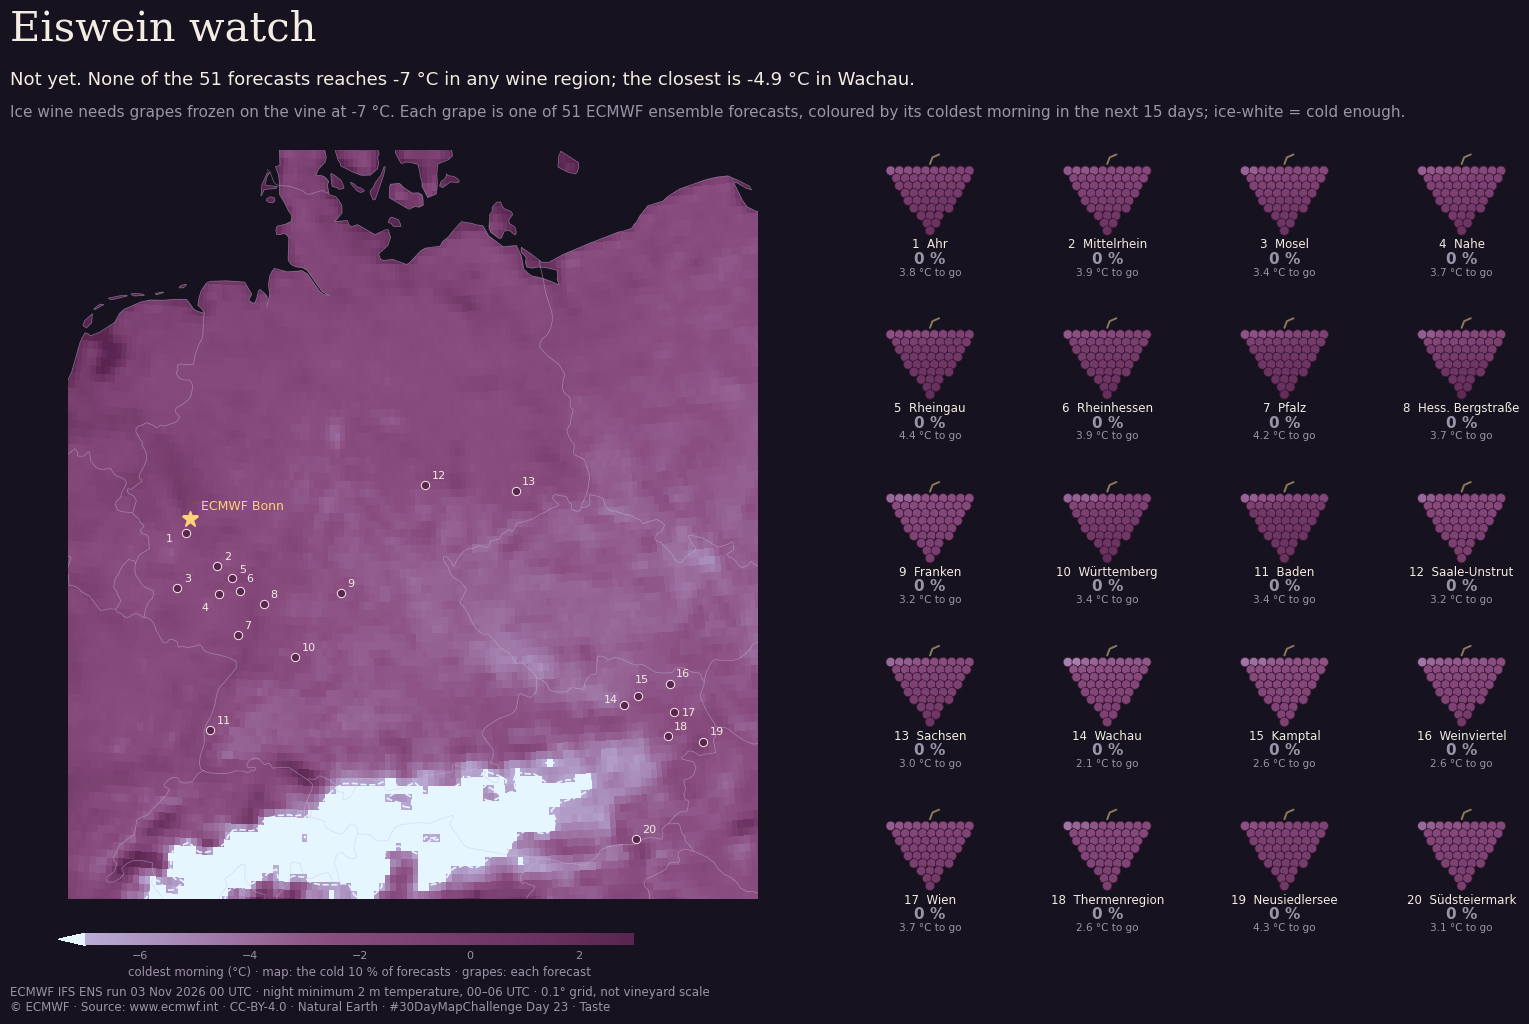

In [8]:
# palette: winter night, grape skin, ice — ONE temperature scale for map and grapes
BG, INK, MUTED = "#17121f", "#f3ece2", "#9d93a8"
ICE, ICE_EDGE, LAND = "#e6f6ff", "#9fd3f0", "#221a2c"
T_WARM = 3.0                                    # °C: at or above this a grape is plain purple
# -7 °C ... +3 °C runs lavender -> grape; anything colder than -7 °C snaps to ice-white,
# so "almost" and "frozen" never look alike
FROST = mcolors.LinearSegmentedColormap.from_list(
    "frost", [(0, "#b9acd6"), (0.45, "#8a4d80"), (1, "#5a2550")]).with_extremes(under=ICE, over="#5a2550")
NORM = mcolors.Normalize(THRESH + 1e-6, T_WARM)

ROWS = [10, 9, 8, 7, 6, 5, 3, 2, 1]          # 51 berries, a bunch shape
assert sum(ROWS) == 51

def bunch_xy(r=1.0):
    pts = []
    for i, n in enumerate(ROWS):
        for j in range(n):
            x = (j - (n - 1) / 2) * 2.1 * r + (0.35 * r if i % 2 else 0)
            pts.append((x, -i * 1.8 * r))
    return np.array(pts)

def draw_bunch(ax, tmin, title, idx):
    xy = bunch_xy()
    t = np.sort(tmin)                          # coldest grapes at the top: reads like a gauge
    iced = t <= THRESH
    ax.plot([0, 0.6, 2.2], [1.6, 3.2, 3.9], color="#8a7a5a", lw=1.4, solid_capstyle="round")
    ax.scatter(*xy.T, s=46, c=FROST(NORM(t)), edgecolors=np.where(iced, ICE_EDGE, "#3a1833"),
               linewidths=np.where(iced, 1.0, 0.5))
    ax.set_xlim(-12, 12); ax.set_ylim(-17.5, 5); ax.set_aspect("equal"); ax.axis("off")
    pct, gap = 100 * iced.mean(), t[0] - THRESH
    ax.text(0, -16.2, f"{idx}  {title}", ha="center", va="top", color=INK, fontsize=8.5)
    ax.text(0, -19.4, f"{pct:.0f} %", ha="center", va="top",
            color=ICE if pct > 0 else MUTED, fontsize=11, fontweight="bold")
    ax.text(0, -23.2, "frozen" if gap <= 0 else f"{gap:.1f} °C to go",
            ha="center", va="top", color=MUTED, fontsize=7.5)

fig = plt.figure(figsize=(16, 10.4), facecolor=BG)
gs = GridSpec(1, 2, width_ratios=[1.15, 1], wspace=0.04, left=0.02, right=0.98, top=0.85, bottom=0.13)

# --- map: the cold edge of the ensemble, with the -7 °C line -----------------
proj = ccrs.LambertConformal(central_longitude=11, central_latitude=50, standard_parallels=(47, 53))
ax = fig.add_subplot(gs[0], projection=proj, facecolor=BG)
ax.set_extent([5.3, 17.6, 45.9, 55.2], crs=ccrs.PlateCarree())
pc = ccrs.PlateCarree()
ax.pcolormesh(cold10.longitude, cold10.latitude, cold10, cmap=FROST, norm=NORM,
              transform=pc, shading="nearest", zorder=1)
if float(cold10.min()) <= THRESH:
    ax.contour(cold10.longitude, cold10.latitude, cold10, levels=[THRESH], colors=ICE,
               linewidths=1.2, transform=pc, zorder=2)
ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=BG, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#cbbfd8", lw=0.5, alpha=0.5, zorder=4)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#cbbfd8", lw=0.5, alpha=0.5, zorder=4)
ax.spines["geo"].set_visible(False)

LABEL_OFFSET = {"Ahr": (-0.38, -0.12), "Nahe": (-0.32, -0.22), "Rheinhessen": (0.12, 0.12),
                "Wachau": (-0.38, 0.05), "Kamptal": (-0.05, 0.16), "Wien": (0.14, -0.05)}
names = list(REGIONS)
for i, name in enumerate(names, 1):
    lat, lon = REGIONS[name]
    dx, dy = LABEL_OFFSET.get(name, (0.12, 0.08))
    ax.plot(lon, lat, "o", ms=6, mfc="#5a2550", mec=INK, mew=0.7, transform=pc, zorder=5)
    ax.text(lon + dx, lat + dy, str(i), color=INK, fontsize=8, transform=pc, zorder=5)
ax.plot(BONN[1], BONN[0], "*", ms=12, color="#ffd27a", transform=pc, zorder=6)
ax.text(BONN[1] + 0.2, BONN[0] + 0.12, "ECMWF Bonn", color="#ffd27a", fontsize=9, transform=pc, zorder=6)

# colour bar under the map, shared by map and grapes
cax = fig.add_axes([0.05, 0.085, 0.36, 0.012])
cb = fig.colorbar(plt.cm.ScalarMappable(NORM, FROST), cax=cax, orientation="horizontal", extend="min")
cb.outline.set_visible(False); cb.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cb.set_label("coldest morning (°C) · map: the cold 10 % of forecasts · grapes: each forecast",
             color=MUTED, fontsize=8.5)

# --- wine list -------------------------------------------------------------
sub = GridSpecFromSubplotSpec(5, 4, subplot_spec=gs[1], hspace=0.75, wspace=0.05)
for i, name in enumerate(names):
    draw_bunch(fig.add_subplot(sub[i // 4, i % 4]), regions[name]["tmin"], name, i + 1)

# --- headline written from the data ------------------------------------------
best = min(regions, key=lambda n: regions[n]["tmin"].min())
tbest = regions[best]["tmin"].min()
n_reg = sum(r["members"].any() for r in regions.values())
if n_reg == 0:                                  # judge by the wine regions, not the Alps
    verdict = (f"Not yet. None of the 51 forecasts reaches {THRESH:.0f} °C in any wine region; "
               f"the closest is {tbest:.1f} °C in {best}.")
else:
    verdict = (f"{n_reg} of {len(regions)} regions have at least one forecast at {THRESH:.0f} °C; "
               f"best odds: {best}.")
fig.text(0.02, 0.955, "Eiswein watch", color=INK, fontsize=30, family="serif")
fig.text(0.02, 0.913, verdict, color=INK, fontsize=13)
fig.text(0.02, 0.882,
         f"Ice wine needs grapes frozen on the vine at {THRESH:.0f} °C. Each grape is one of 51 ECMWF ensemble "
         f"forecasts, coloured by its coldest morning in the next {N_DAYS} days; ice-white = cold enough.",
         color=MUTED, fontsize=11)
fig.text(0.02, 0.022,
         f"ECMWF IFS ENS run {RUN:%d %b %Y %H} UTC · {FIELD} · {GRID} grid, not vineyard scale\n"
         "© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 · Natural Earth · #30DayMapChallenge Day 23 · Taste",
         color=MUTED, fontsize=8.5)

fig.savefig(OUT, dpi=200, facecolor=BG)
plt.show()

## Bonus: the frost calendar

Morning by morning: how cold does the coldest forecast get, and when?

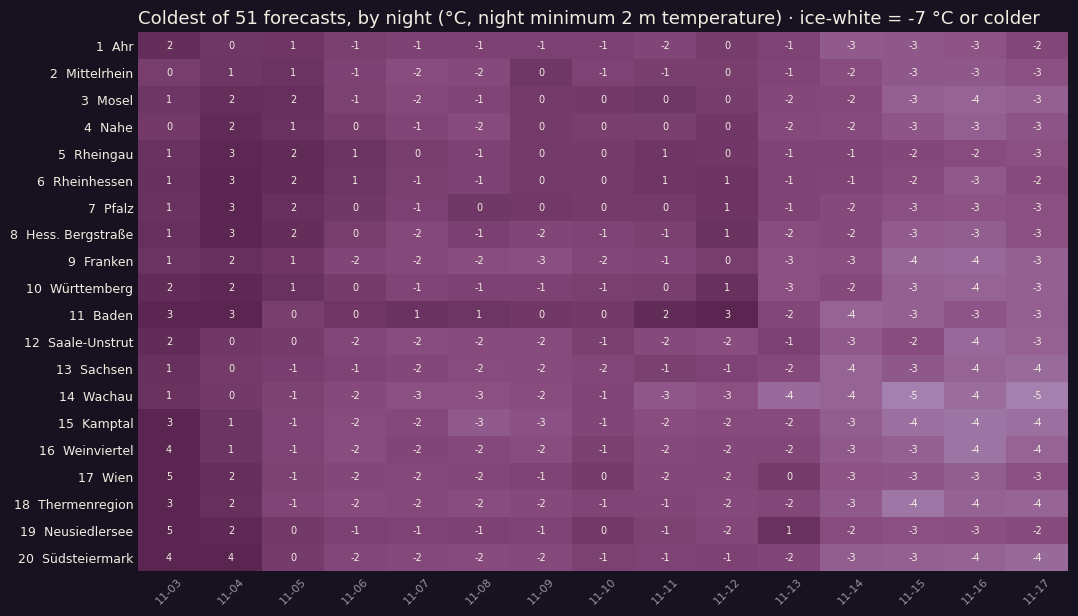

In [9]:
daily = np.array([regions[n]["day_min"] for n in names])     # region x morning, °C
days = [np.datetime64(RUN, "D") + np.timedelta64(d, "D") for d in range(N_DAYS)]

fig2, ax2 = plt.subplots(figsize=(12, 7), facecolor=BG)
ax2.set_facecolor(BG)
ax2.imshow(daily, cmap=FROST, norm=NORM, aspect="auto")
ax2.set_yticks(range(len(names)), [f"{i+1}  {n}" for i, n in enumerate(names)], color=INK, fontsize=9)
ax2.set_xticks(range(N_DAYS), [str(d)[5:] for d in days], color=MUTED, fontsize=8, rotation=45)
for s_ in ax2.spines.values(): s_.set_visible(False)
ax2.tick_params(length=0)
ax2.set_title(f"Coldest of 51 forecasts, by night (°C, {FIELD.split(',')[0]}) · ice-white = {THRESH:.0f} °C or colder",
              color=INK, loc="left", fontsize=13)
for (i, j), v in np.ndenumerate(daily):
    ax2.text(j, i, f"{int(round(float(v)))}", ha="center", va="center", fontsize=7,
             color=BG if v <= THRESH else INK)
fig2.savefig("day23_taste_eiswein_calendar.png", dpi=200, facecolor=BG, bbox_inches="tight")
plt.show()

## Output

`day23_taste_eiswein.png` (poster) and `day23_taste_eiswein_calendar.png` (frost calendar).

*Posting idea:* "Ice wine needs −7 °C. We're in Bonn, about 25 km from the Ahr, one of
the world's northernmost red-wine valleys. Here's what 51 versions of the next two weeks say.